In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import joblib

In [2]:
# ============================================================
# Load Merged Dataset
# ============================================================

ds = xr.open_dataset("merged_glory_chla_colocated_100-Copy3.nc")

#print(ds)

In [3]:
# ============================================================
# Bay Of Bengal Region
# ============================================================

ds = ds.sel(
    latitude=slice(5, 25),
    longitude=slice(78, 100)
)

print(ds)


print(ds.latitude.min().values)
print(ds.latitude.max().values)

print(ds.longitude.min().values)
print(ds.longitude.max().values)

<xarray.Dataset> Size: 2GB
Dimensions:      (time: 339, latitude: 241, longitude: 265)
Coordinates:
  * latitude     (latitude) float32 964B 5.0 5.083 5.167 ... 24.83 24.92 25.0
  * longitude    (longitude) float32 1kB 78.0 78.08 78.17 ... 99.83 99.92 100.0
  * time         (time) datetime64[ns] 3kB 1997-10-01 1997-11-01 ... 2025-12-01
Data variables:
    zos          (time, latitude, longitude) float64 173MB ...
    so           (time, latitude, longitude) float64 173MB ...
    thetao       (time, latitude, longitude) float64 173MB ...
    uo           (time, latitude, longitude) float64 173MB ...
    vo           (time, latitude, longitude) float64 173MB ...
    mlotst       (time, latitude, longitude) float64 173MB ...
    vorticity    (time, latitude, longitude) float64 173MB ...
    okubo_weiss  (time, latitude, longitude) float64 173MB ...
    grad_ssh     (time, latitude, longitude) float64 173MB ...
    chlor_a      (time, latitude, longitude) float32 87MB ...
Attributes:
    h

In [4]:
# ============================================================
# Select 2025
# ============================================================

ds_2025 = ds.sel(
    time=slice(
        "2025-01-01",
        "2025-12-01"
    )
)

print(ds_2025)
print(ds_2025.time.values)

<xarray.Dataset> Size: 58MB
Dimensions:      (time: 12, latitude: 241, longitude: 265)
Coordinates:
  * latitude     (latitude) float32 964B 5.0 5.083 5.167 ... 24.83 24.92 25.0
  * longitude    (longitude) float32 1kB 78.0 78.08 78.17 ... 99.83 99.92 100.0
  * time         (time) datetime64[ns] 96B 2025-01-01 2025-02-01 ... 2025-12-01
Data variables:
    zos          (time, latitude, longitude) float64 6MB ...
    so           (time, latitude, longitude) float64 6MB ...
    thetao       (time, latitude, longitude) float64 6MB ...
    uo           (time, latitude, longitude) float64 6MB ...
    vo           (time, latitude, longitude) float64 6MB ...
    mlotst       (time, latitude, longitude) float64 6MB ...
    vorticity    (time, latitude, longitude) float64 6MB ...
    okubo_weiss  (time, latitude, longitude) float64 6MB ...
    grad_ssh     (time, latitude, longitude) float64 6MB ...
    chlor_a      (time, latitude, longitude) float32 3MB ...
Attributes:
    history:            

In [5]:
# ============================================================
# Log10 Chlorophyll
# ============================================================

ds_2025["chlor_a_log10"] = xr.where(
    ds_2025["chlor_a"] > 0,
    np.log10(ds_2025["chlor_a"]),
    np.nan
)


# ============================================================
# Natural Log MLD
# ============================================================

ds_2025["mlotst_ln"] = xr.where(
    ds_2025["mlotst"] > 0,
    np.log(ds_2025["mlotst"]),
    np.nan
)

In [6]:
# ============================================================
# Month Feature
# ============================================================

month = ds_2025.time.dt.month

# ============================================================
# Cyclic Month Features
# ============================================================

ds_2025["month_sin"] = xr.DataArray(
    np.sin(2*np.pi*month/12),
    coords={"time": ds_2025.time},
    dims=["time"]
)

ds_2025["month_cos"] = xr.DataArray(
    np.cos(2*np.pi*month/12),
    coords={"time": ds_2025.time},
    dims=["time"]
)

In [7]:
# ============================================================
# Expand Month Features
# ============================================================

month_sin_3d = ds_2025["month_sin"].broadcast_like(ds_2025["zos"])

month_cos_3d = ds_2025["month_cos"].broadcast_like(ds_2025["zos"])

In [8]:
# ============================================================
# Feature Stack
# ============================================================

feature_stack = np.stack(
    [
        month_sin_3d.values,
        month_cos_3d.values,
        #ds_2025["zos"].values,
        ds_2025["so"].values,
        ds_2025["thetao"].values,
        ds_2025["uo"].values,
        ds_2025["vo"].values,
        ds_2025["mlotst_ln"].values,
        ds_2025["vorticity"].values,
        ds_2025["okubo_weiss"].values
        #ds_2025["grad_ssh"].values
    ],
    axis=-1
)

print(feature_stack.shape)

(12, 241, 265, 9)


In [9]:
# ============================================================
# Valid Ocean Mask
# ============================================================

valid_mask = np.isfinite(feature_stack).all(axis=-1)

print(valid_mask.shape)

(12, 241, 265)


In [10]:
FEATURES = [
    "month_sin",
    "month_cos",
    #"zos",
    "so",
    "thetao",
    "uo",
    "vo",
    "mlotst_ln",
    "vorticity",
    "okubo_weiss"
    #"grad_ssh"
]

X_pred = pd.DataFrame(
    feature_stack[valid_mask],
    columns=FEATURES
).astype("float32")

In [11]:
UNDER_PENALTY = 0.007

def underestimation_loss(y_true, y_pred):

    error = y_true - y_pred

    under_mask = error > 0

    grad = np.where(
        under_mask,
        -2.0 * (1.0 + UNDER_PENALTY) * error,
        -2.0 * error
    )

    hess = np.where(
        under_mask,
        2.0 * (1.0 + UNDER_PENALTY),
        2.0
    )

    return grad, hess

In [12]:
# ============================================================
# Load Trained XGBoost Model
# ============================================================

import joblib

model = joblib.load(
    "xgboost_BoB_NO_SSH_model.pkl"
)

In [13]:
# ============================================================
# Prediction
# ============================================================

pred_log10 = model.predict(X_pred)

print(pred_log10.shape)

(445908,)


In [14]:
# ============================================================
# Rebuild Grid
# ============================================================

pred_grid_log10 = np.full(
    valid_mask.shape,
    np.nan,
    dtype=np.float32
)

pred_grid_log10[valid_mask] = pred_log10

In [15]:
# ============================================================
# Back Transform
# ============================================================

pred_grid_chl = np.power(
    10,
    pred_grid_log10
)

In [16]:
# ============================================================
# Add Predictions
# ============================================================

ds_2025["chlor_a_pred_log10"] = (
    ("time","latitude","longitude"),
    pred_grid_log10
)

ds_2025["chlor_a_pred"] = (
    ("time","latitude","longitude"),
    pred_grid_chl
)

In [17]:
true_log = ds_2025["chlor_a_log10"]

pred_log = ds_2025["chlor_a_pred_log10"]

In [18]:
# ============================================================
# Error
# ============================================================

ds_2025["prediction_error"] = (
    ds_2025["chlor_a_pred_log10"]
    -
    ds_2025["chlor_a_log10"]
)


In [19]:
import xarray as xr
import xskillscore as xs
import matplotlib.pyplot as plt

/home/prasanna/anaconda3/envs/mlenv/lib/python3.10/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den


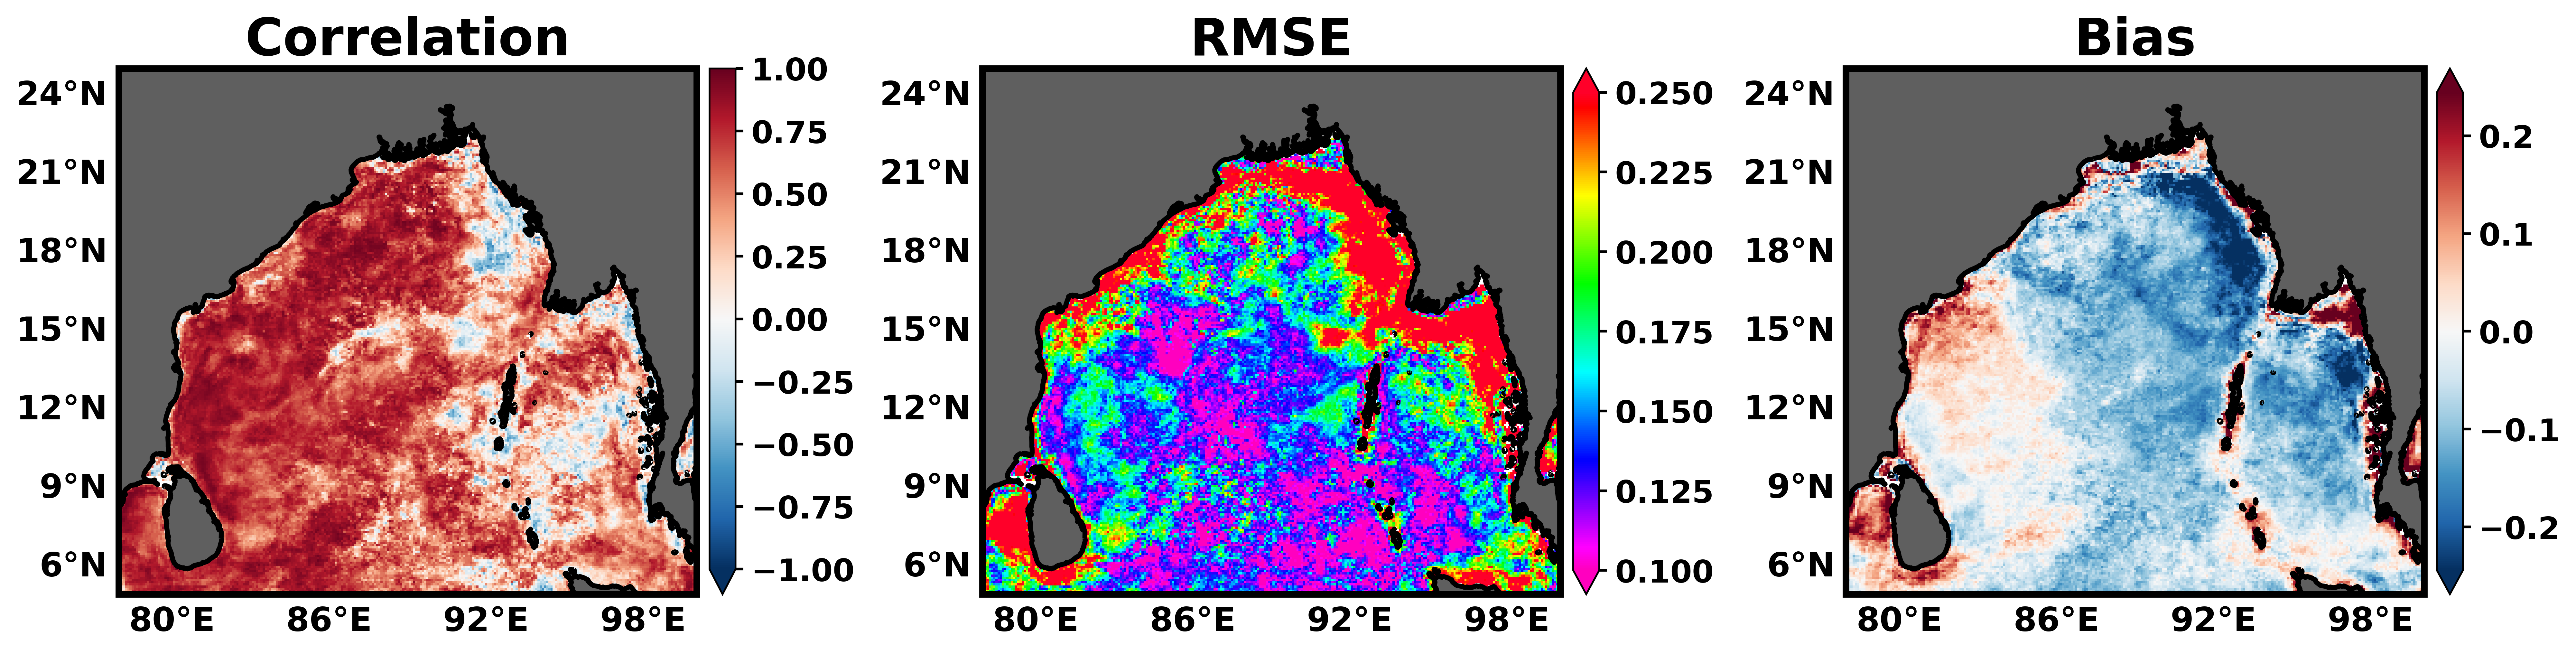

In [22]:
# logged

# ==========================================================
# Spatial Performance Maps
# Correlation | RMSE | Bias
# ==========================================================

import matplotlib.ticker as mticker
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xskillscore as xs

# ==========================================================
# Compute Metrics
# ==========================================================
corr_map = xs.pearson_r(
    true_log,
    pred_log,
    dim="time",
    skipna=True
)

rmse_map = xs.rmse(
    true_log,
    pred_log,
    dim="time",
    skipna=True
)

bias_map = xs.me(
    true_log,
    pred_log,
    dim="time",
    skipna=True
)







# ==========================================================
# Global Plot Settings
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"

# ==========================================================
# Create Figure
# ==========================================================

fig, ax = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15.5, 9),
    dpi=500,
    subplot_kw={"projection": ccrs.PlateCarree()}
)


# ==========================================================
# Correlation Map
# ==========================================================

corr_plot = corr_map.plot(
    ax=ax[0],
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    robust=True,
    add_colorbar=False,
    
)
divider0 = make_axes_locatable(ax[0])
cax0 = divider0.append_axes(
    "right",
    size="4.5%",
    pad=0.08,
    axes_class=plt.Axes
)

cbar0 = fig.colorbar(
    corr_plot,
    cax=cax0,
    extend="min"
)




ax[0].set_title(
    "Correlation",
    fontsize=23,
    fontweight="bold"
)

# ==========================================================
# RMSE Map
# ==========================================================

rmse_plot = rmse_map.plot(
    ax=ax[1],
    transform=ccrs.PlateCarree(),
    cmap="gist_rainbow_r",          
    vmin=0.10,
    vmax=0.25,
    add_colorbar=False,
    
)

divider1 = make_axes_locatable(ax[1])
cax1 = divider1.append_axes(
    "right",
    size="4.5%",
    pad=0.08,
    axes_class=plt.Axes
)

cbar1 = fig.colorbar(
    rmse_plot,
    cax=cax1,
    extend="both"
    #ticks=[0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
)



ax[1].set_title(
    "RMSE",
    fontsize=23,
    fontweight="bold"
)

# ==========================================================
# Bias Map
# ==========================================================

bias_plot = bias_map.plot(
    ax=ax[2],
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    center=0,
    robust=True,
    add_colorbar=False,
    
)

divider2 = make_axes_locatable(ax[2])
cax2 = divider2.append_axes(
    "right",
    size="4.5%",
    pad=0.08,
    axes_class=plt.Axes
)

cbar2 = fig.colorbar(
    bias_plot,
    cax=cax2,
    extend="both"
)

ax[2].set_title(
    "Bias",
    fontsize=23,
    fontweight="bold"
)

# ==========================================================
# Coastlines, Land, Gridlines, Tick Styling
# ==========================================================

for a in ax:

    # --------------------------------------
    # Grey Land
    # --------------------------------------

    a.add_feature(
        cfeature.LAND,
        facecolor="#5f5f5f",
        edgecolor="none",
        zorder=0
    )

    # --------------------------------------
    # Black Coastlines
    # --------------------------------------

    a.coastlines(
        resolution="10m",
        color="black",
        linewidth=2.2
    )
    
    
    
    # Bold subplot boundary
    for spine in a.spines.values():
        spine.set_linewidth(3.0)
        spine.set_edgecolor("black")

    # --------------------------------------
    # Latitude / Longitude Labels
    # --------------------------------------

    gl = a.gridlines(
        draw_labels=True,
        linewidth=0.0,
        linestyle="--",
        alpha=0.5
    )

    #gl.x

    gl.top_labels = False
    gl.right_labels = False
    
    gl.xlocator = mticker.FixedLocator([80, 86, 92, 98])

    gl.xlabel_style = {
        "size": 15,
        "weight": "bold"
    }

    gl.ylabel_style = {
        "size": 15,
        "weight": "bold"
    }

    # --------------------------------------
    # Bold Tick Labels
    # --------------------------------------

    for label in a.get_xticklabels():
        label.set_fontweight("bold")
        label.set_fontsize(13)

    for label in a.get_yticklabels():
        label.set_fontweight("bold")
        label.set_fontsize(13)

# ==========================================================
# Make Colorbar Tick Labels Bold
# ==========================================================

for cbar in [cbar0, cbar1, cbar2]:

    cbar.ax.tick_params(
        labelsize=14,
        width=1.2
    )

    for tick in cbar.ax.get_yticklabels():
        tick.set_fontweight("bold")

# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    left=0.04,
    right=0.98,
    bottom=0.08,
    top=0.92,
    wspace=0.40
)

plt.show()

In [21]:
print(rmse_map.mean())
print(corr_map.mean())
print(bias_map.mean())

<xarray.DataArray ()> Size: 4B
array(0.1747423, dtype=float32)
<xarray.DataArray ()> Size: 4B
array(0.52722883, dtype=float32)
<xarray.DataArray ()> Size: 4B
array(-0.04779547, dtype=float32)


In [ ]:
# logged

# ==========================================================
# Spatial Performance Maps
# Correlation | RMSE | Bias
# ==========================================================
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xskillscore as xs

# ==========================================================
# Compute Metrics
# ==========================================================

corr_map = xs.pearson_r(
    ds_2025["chlor_a_pred_log10"],
    ds_2025["chlor_a_log10"],
    dim="time",
    skipna=True
)

rmse_map = xs.rmse(
    ds_2025["chlor_a_pred_log10"],
    ds_2025["chlor_a_log10"],
    dim="time",
    skipna=True
)

bias_map = xs.me(
    ds_2025["chlor_a_pred_log10"],
    ds_2025["chlor_a_log10"],
    dim="time",
    skipna=True
)

# ==========================================================
# Global Plot Settings
# ==========================================================

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"

# ==========================================================
# Create Figure
# ==========================================================

fig, ax = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15.5, 7),
    dpi=1500,
    subplot_kw={"projection": ccrs.PlateCarree()}
)


# ==========================================================
# Correlation Map
# ==========================================================

corr_plot = corr_map.plot(
    ax=ax[0],
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    robust=True,
    add_colorbar=False,
    
)
divider0 = make_axes_locatable(ax[0])
cax0 = divider0.append_axes(
    "right",
    size="4.5%",
    pad=0.08,
    axes_class=plt.Axes
)

cbar0 = fig.colorbar(
    corr_plot,
    cax=cax0
)




ax[0].set_title(
    "Correlation",
    fontsize=19,
    fontweight="bold"
)

# ==========================================================
# RMSE Map
# ==========================================================

rmse_plot = rmse_map.plot(
    ax=ax[1],
    transform=ccrs.PlateCarree(),
    cmap="gist_rainbow_r",          
    vmin=0,
    vmax=0.3,
    add_colorbar=False,
    
)

divider1 = make_axes_locatable(ax[1])
cax1 = divider1.append_axes(
    "right",
    size="4.5%",
    pad=0.08,
    axes_class=plt.Axes
)

cbar1 = fig.colorbar(
    rmse_plot,
    cax=cax1,
    extend="max",
    ticks=[0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
)



ax[1].set_title(
    "RMSE",
    fontsize=19,
    fontweight="bold"
)

# ==========================================================
# Bias Map
# ==========================================================

bias_plot = bias_map.plot(
    ax=ax[2],
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    center=0,
    robust=True,
    add_colorbar=False,
    
)

divider2 = make_axes_locatable(ax[2])
cax2 = divider2.append_axes(
    "right",
    size="4.5%",
    pad=0.08,
    axes_class=plt.Axes
)

cbar2 = fig.colorbar(
    bias_plot,
    cax=cax2,
    extend="both"
)

ax[2].set_title(
    "Bias",
    fontsize=19,
    fontweight="bold"
)

# ==========================================================
# Coastlines, Land, Gridlines, Tick Styling
# ==========================================================

for a in ax:

    # --------------------------------------
    # Grey Land
    # --------------------------------------

    a.add_feature(
        cfeature.LAND,
        facecolor="#5f5f5f",
        edgecolor="none",
        zorder=0
    )

    # --------------------------------------
    # Black Coastlines
    # --------------------------------------

    a.coastlines(
        resolution="10m",
        color="black",
        linewidth=2.0
    )

    # --------------------------------------
    # Latitude / Longitude Labels
    # --------------------------------------

    gl = a.gridlines(
        draw_labels=True,
        linewidth=0.5,
        linestyle="--",
        alpha=0.5
    )

    gl.top_labels = False
    gl.right_labels = False

    gl.xlabel_style = {
        "size": 15,
        "weight": "bold"
    }

    gl.ylabel_style = {
        "size": 15,
        "weight": "bold"
    }

    # --------------------------------------
    # Bold Tick Labels
    # --------------------------------------

    for label in a.get_xticklabels():
        label.set_fontweight("bold")
        label.set_fontsize(13)

    for label in a.get_yticklabels():
        label.set_fontweight("bold")
        label.set_fontsize(13)

# ==========================================================
# Make Colorbar Tick Labels Bold
# ==========================================================

for cbar in [cbar0, cbar1, cbar2]:

    cbar.ax.tick_params(
        labelsize=14,
        width=1.2
    )

    for tick in cbar.ax.get_yticklabels():
        tick.set_fontweight("bold")

# ==========================================================
# Layout
# ==========================================================

plt.subplots_adjust(
    left=0.04,
    right=0.98,
    bottom=0.08,
    top=0.92,
    wspace=0.2
)

plt.show()

In [22]:
print(ds_2025.dims)
print(ds_2025.coords)

Frozen({'time': 12, 'latitude': 241, 'longitude': 265})
Coordinates:
  * latitude   (latitude) float32 5.0 5.083 5.167 5.25 ... 24.83 24.92 25.0
  * longitude  (longitude) float32 78.0 78.08 78.17 78.25 ... 99.83 99.92 100.0
  * time       (time) datetime64[ns] 2025-01-01 2025-02-01 ... 2025-12-01


In [23]:
rmse_map.mean()



<xarray.DataArray ()>
array(0.21314313, dtype=float32)

In [24]:
corr_map.mean()

<xarray.DataArray ()>
array(0.4903844, dtype=float32)

In [25]:
bias_map.mean()

<xarray.DataArray ()>
array(-0.0246112, dtype=float32)

/tmp/ipykernel_7992/1966975733.py:258: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


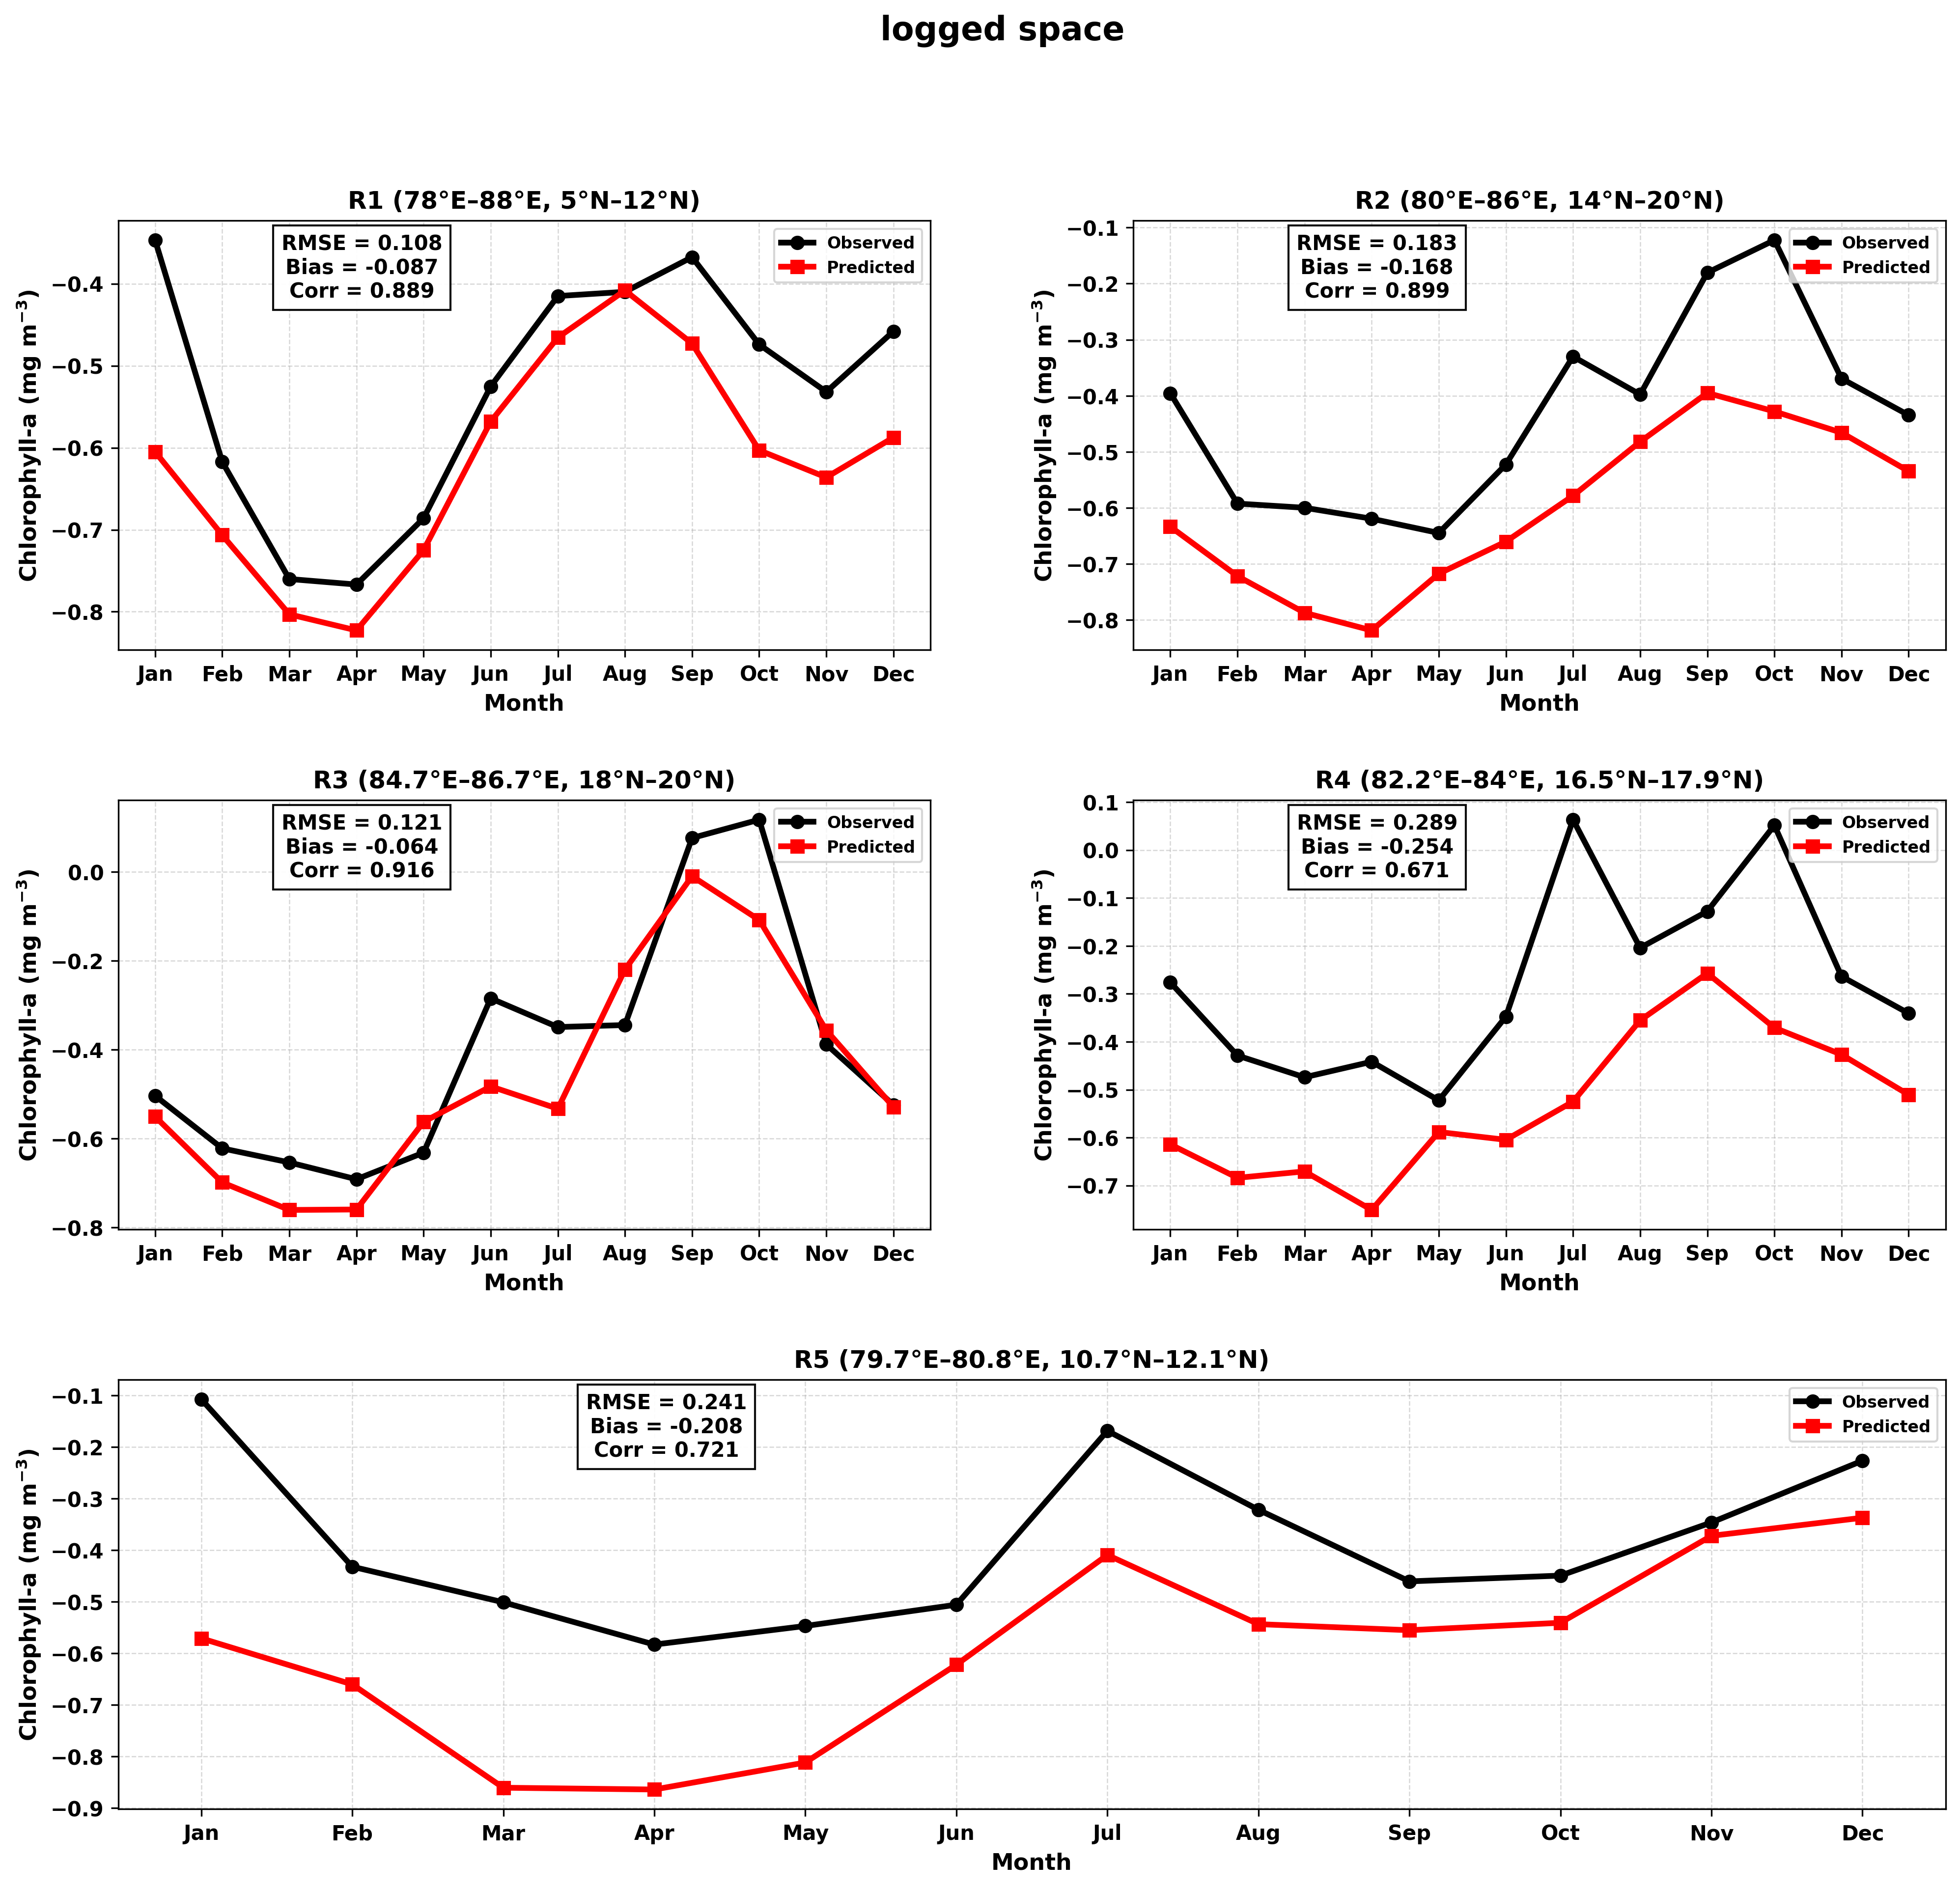

In [30]:
# ==========================================================
# Regional Monthly Chl-a Comparison
# Layout:
#
# R1   R2
# R3   R4
#   R5
#
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error

# ==========================================================
# Subregions
# ==========================================================

regions = {
    "R1 (78°E–88°E, 5°N–12°N)": [78.0, 88.0, 5.0, 12.0],
    "R2 (80°E–86°E, 14°N–20°N)": [80.0, 86.0, 14.0, 20.0],
    "R3 (84.7°E–86.7°E, 18°N–20°N)": [84.7, 86.7, 18.0, 20.0],
    "R4 (82.2°E–84°E, 16.5°N–17.9°N)": [82.2, 84.0, 16.5, 17.9],
    "R5 (79.7°E–80.8°E, 10.7°N–12.1°N)": [79.7, 80.8, 10.7, 12.1]
}

# ==========================================================
# Month Labels
# ==========================================================

months = [
    "Jan","Feb","Mar","Apr",
    "May","Jun","Jul","Aug",
    "Sep","Oct","Nov","Dec"
]

# ==========================================================
# Create Figure Layout
# ==========================================================

fig = plt.figure(
    figsize=(16, 14),
    dpi=300
)

gs = fig.add_gridspec(
    3, 2,
    hspace=0.35,
    wspace=0.25
)

axes = [
    fig.add_subplot(gs[0, 0]),  # R1
    fig.add_subplot(gs[0, 1]),  # R2
    fig.add_subplot(gs[1, 0]),  # R3
    fig.add_subplot(gs[1, 1]),  # R4
    fig.add_subplot(gs[2, :])   # R5 spans full width
]

# ==========================================================
# Loop Through Regions
# ==========================================================

for ax, (region_name, box) in zip(axes, regions.items()):

    lon1, lon2, lat1, lat2 = box

    # ------------------------------------------------------
    # Regional subset
    # ------------------------------------------------------

    ds_reg = ds_2025.sel(
        longitude=slice(lon1, lon2),
        latitude=slice(lat1, lat2)
    )

    # ------------------------------------------------------
    # Monthly Regional Means
    # ------------------------------------------------------

    obs_monthly = np.log10(
        ds_reg["chlor_a"]
        .mean(
            dim=["latitude", "longitude"],
            skipna=True
        )
        .values
    )

    pred_monthly = np.log10(
        ds_reg["chlor_a_pred"]
        .mean(
            dim=["latitude", "longitude"],
            skipna=True
        )
        .values
    )

    # ------------------------------------------------------
    # Metrics
    # ------------------------------------------------------

    valid = (
        np.isfinite(obs_monthly)
        &
        np.isfinite(pred_monthly)
    )

    obs_valid = obs_monthly[valid]
    pred_valid = pred_monthly[valid]

    rmse = np.sqrt(
        mean_squared_error(
            obs_valid,
            pred_valid
        )
    )

    bias = np.mean(
        pred_valid - obs_valid
    )

    corr = np.corrcoef(
        obs_valid,
        pred_valid
    )[0, 1]

    # ------------------------------------------------------
    # Observed
    # ------------------------------------------------------

    ax.plot(
        months,
        obs_monthly,
        color="black",
        linewidth=2.8,
        marker="o",
        markersize=6,
        label="Observed"
    )

    # ------------------------------------------------------
    # Predicted
    # ------------------------------------------------------

    ax.plot(
        months,
        pred_monthly,
        color="red",
        linewidth=2.8,
        marker="s",
        markersize=6,
        label="Predicted"
    )

    # ------------------------------------------------------
    # Statistics Box
    # ------------------------------------------------------

    metric_text = (
        f"RMSE = {rmse:.3f}\n"
        f"Bias = {bias:.3f}\n"
        f"Corr = {corr:.3f}"
    )

    ax.text(
        0.30,
        0.97,
        metric_text,
        transform=ax.transAxes,
        fontsize=10,
        fontweight="bold",
        va="top",
        ha="center",
        bbox=dict(
            facecolor="white",
            edgecolor="black",
            alpha=0.95
        )
    )

    # ------------------------------------------------------
    # Titles
    # ------------------------------------------------------

    ax.set_title(
        region_name,
        fontsize=12,
        fontweight="bold"
    )

    # ------------------------------------------------------
    # Labels
    # ------------------------------------------------------

    ax.set_xlabel(
        "Month",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        r"Chlorophyll-a (mg m$^{-3}$)",
        fontsize=11,
        fontweight="bold"
    )

    # ------------------------------------------------------
    # Grid
    # ------------------------------------------------------

    ax.grid(
        linestyle="--",
        linewidth=0.6,
        alpha=0.5
    )

    # ------------------------------------------------------
    # Tick Formatting
    # ------------------------------------------------------

    ax.tick_params(
        axis='both',
        labelsize=10
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    # ------------------------------------------------------
    # Legend
    # ------------------------------------------------------

    ax.legend(
        loc="upper right",
        prop={
            "weight": "bold",
            "size": 8
        }
    )

# ==========================================================
# Global Figure Title
# ==========================================================

fig.suptitle(
    "logged space",
    #"Monthly Mean Chlorophyll-a: Observed vs Predicted Across Bay of Bengal Subregions",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

plt.show()